<a href="https://colab.research.google.com/github/SIMETHY/DV-LAB/blob/main/Program4_dv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pandas.plotting import parallel_coordinates

import warnings
warnings.filterwarnings('ignore')

plt.style.use('ggplot')

In [26]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=';')

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Description:")
display(df.describe())

Dataset loaded successfully!

First 5 rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Dataset Shape: (1599, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None

Statistical Description:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [27]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Features
X = df.drop('quality', axis=1)

# Target class
y = df['quality']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data preprocessing completed!")
print("Feature Shape:", X_scaled.shape)

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Data preprocessing completed!
Feature Shape: (1599, 11)


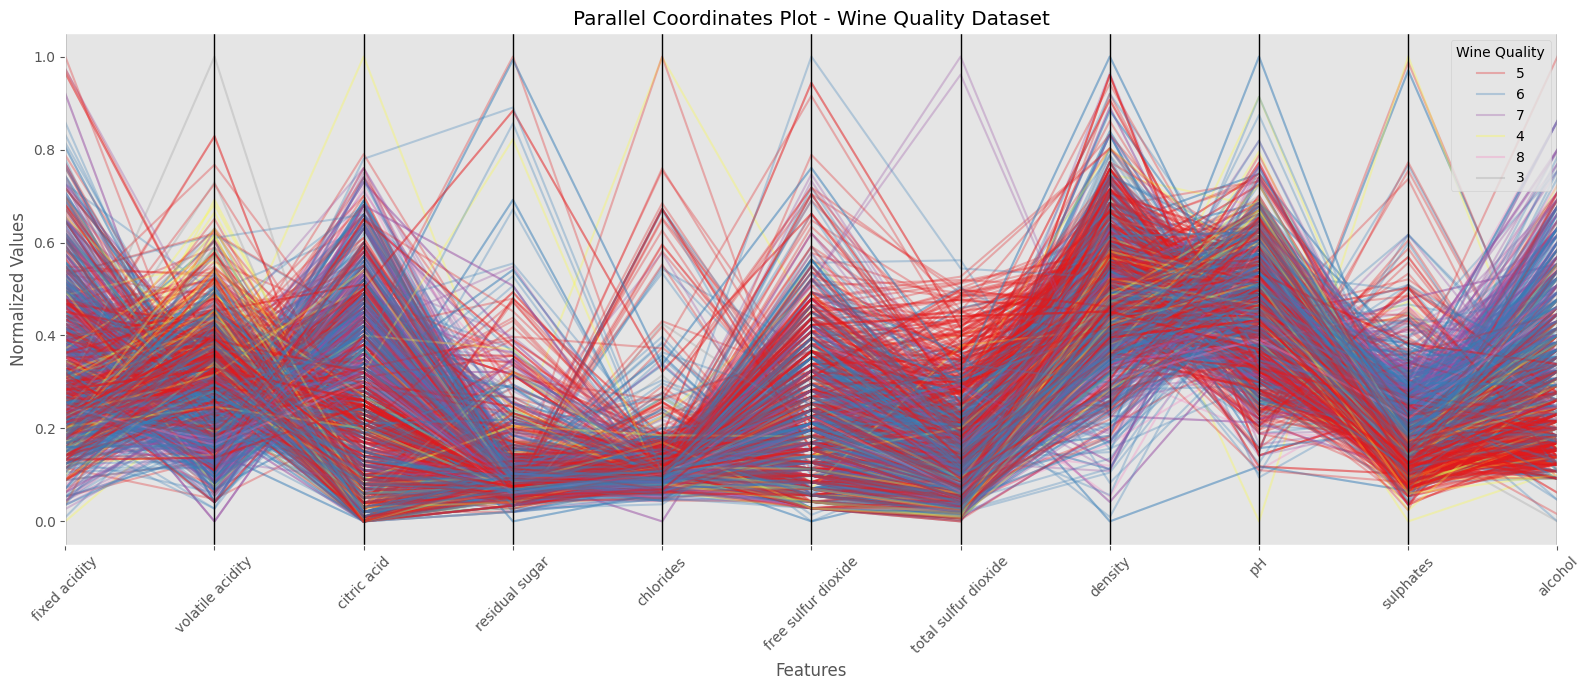

In [28]:
plt.figure(figsize=(16, 7))

# Create a copy for visualization
parallel_df = df.copy()

# Normalize numerical features
for col in parallel_df.columns[:-1]:
    parallel_df[col] = (
        parallel_df[col] - parallel_df[col].min()
    ) / (
        parallel_df[col].max() - parallel_df[col].min()
    )

# Convert quality into categorical values
parallel_df['quality'] = parallel_df['quality'].astype(str)

parallel_coordinates(
    parallel_df,
    class_column='quality',
    colormap=plt.cm.Set1,
    alpha=0.3
)

plt.title("Parallel Coordinates Plot - Wine Quality Dataset")
plt.xlabel("Features")
plt.ylabel("Normalized Values")
plt.xticks(rotation=45)
plt.legend(title="Wine Quality")
plt.tight_layout()
plt.show()

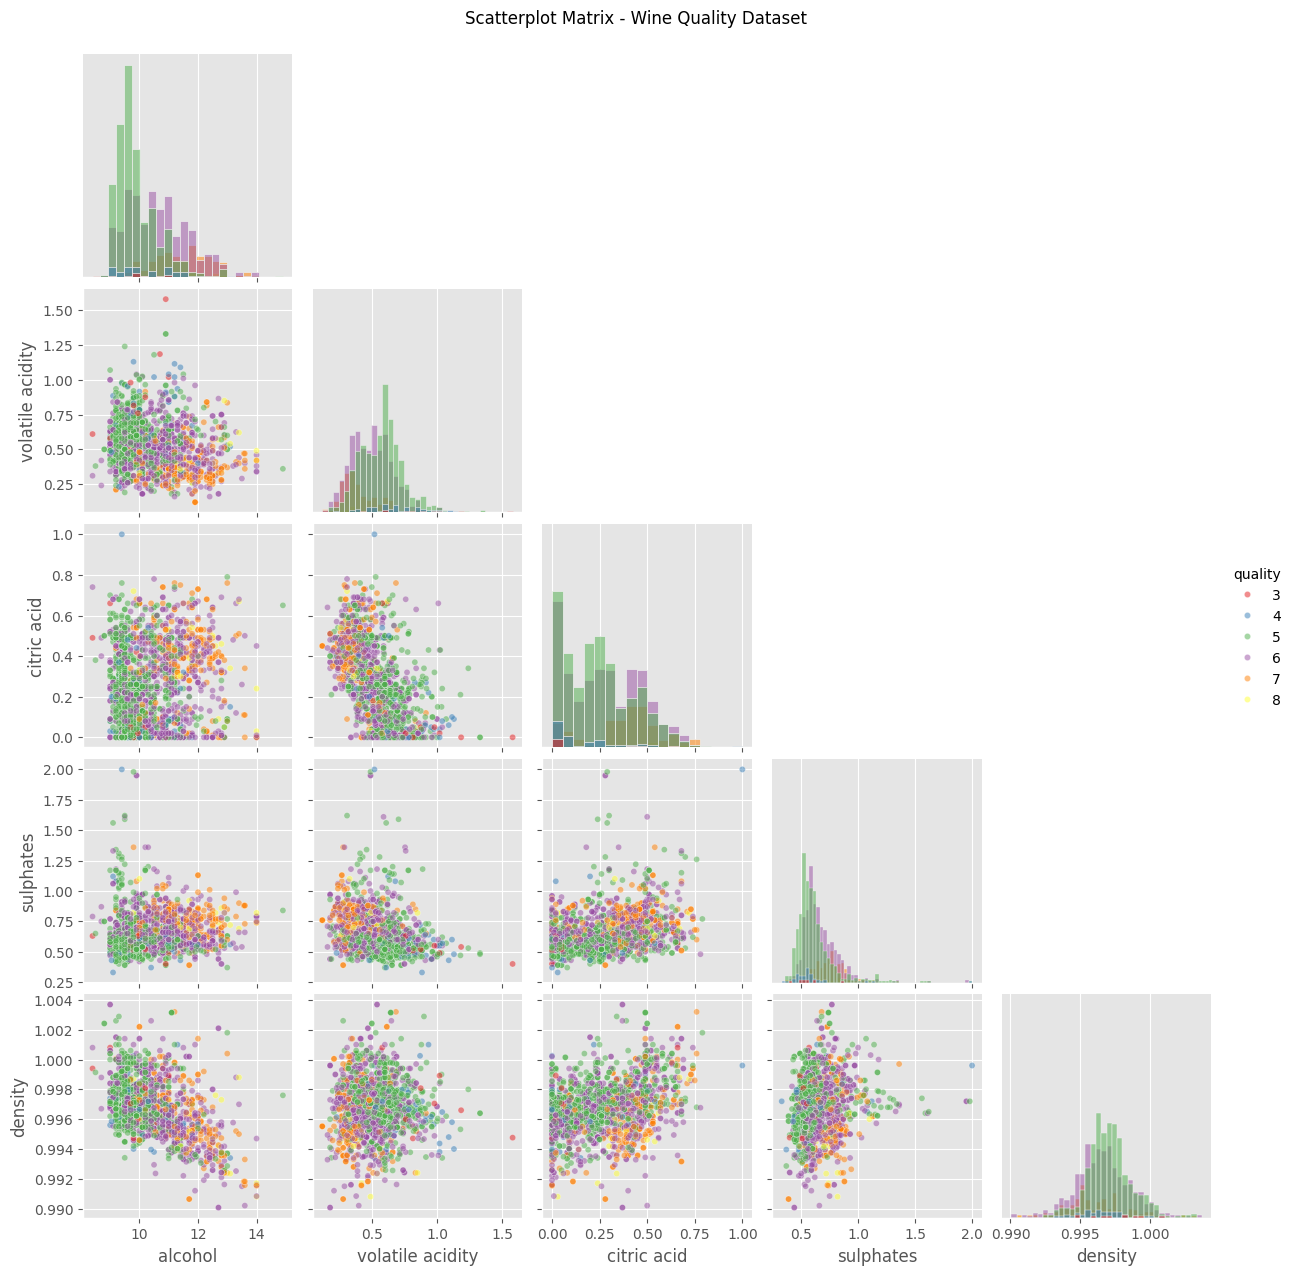

In [29]:
# Select important features
selected_features = [
    'alcohol',
    'volatile acidity',
    'citric acid',
    'sulphates',
    'density',
    'quality'
]

sns.pairplot(
    df[selected_features],
    hue='quality',
    palette='Set1',
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.5, 's': 20}
)

plt.suptitle(
    "Scatterplot Matrix - Wine Quality Dataset",
    y=1.02
)

plt.show()

In [30]:
# Apply PCA on standardized data
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("PCA Transformation Completed!")

print("Original Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

PCA Transformation Completed!
Original Dimensions: (1599, 11)
Reduced Dimensions: (1599, 11)

Explained Variance Ratio:
[0.28173931 0.1750827  0.1409585  0.11029387 0.08720837 0.05996439
 0.05307193 0.03845061 0.0313311  0.01648483 0.00541439]


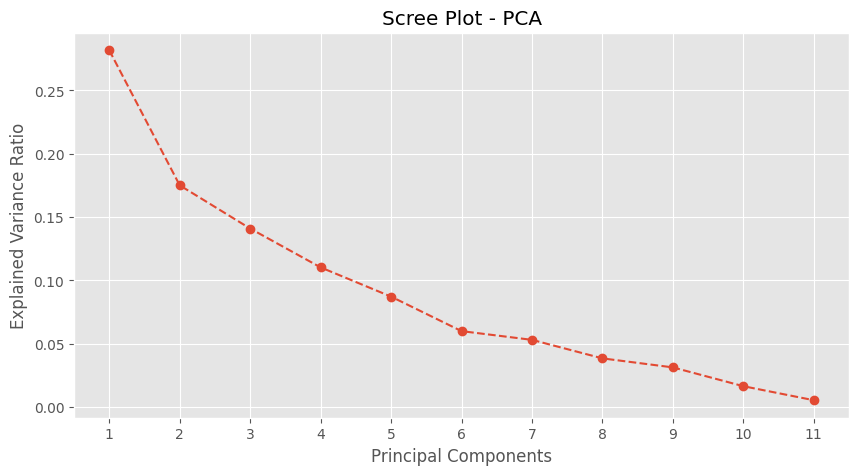

In [31]:
explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o',
    linestyle='--'
)

plt.title("Scree Plot - PCA")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)

plt.show()

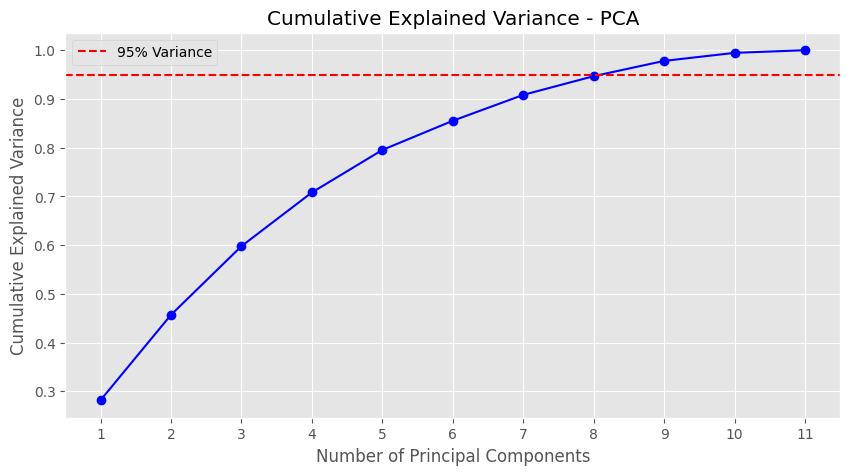

Cumulative Variance:
PC1: 0.2817
PC2: 0.4568
PC3: 0.5978
PC4: 0.7081
PC5: 0.7953
PC6: 0.8552
PC7: 0.9083
PC8: 0.9468
PC9: 0.9781
PC10: 0.9946
PC11: 1.0000


In [32]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    color='blue'
)

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.title("Cumulative Explained Variance - PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True)

plt.show()

print("Cumulative Variance:")
for i, value in enumerate(cumulative_variance):
    print(f"PC{i+1}: {value:.4f}")

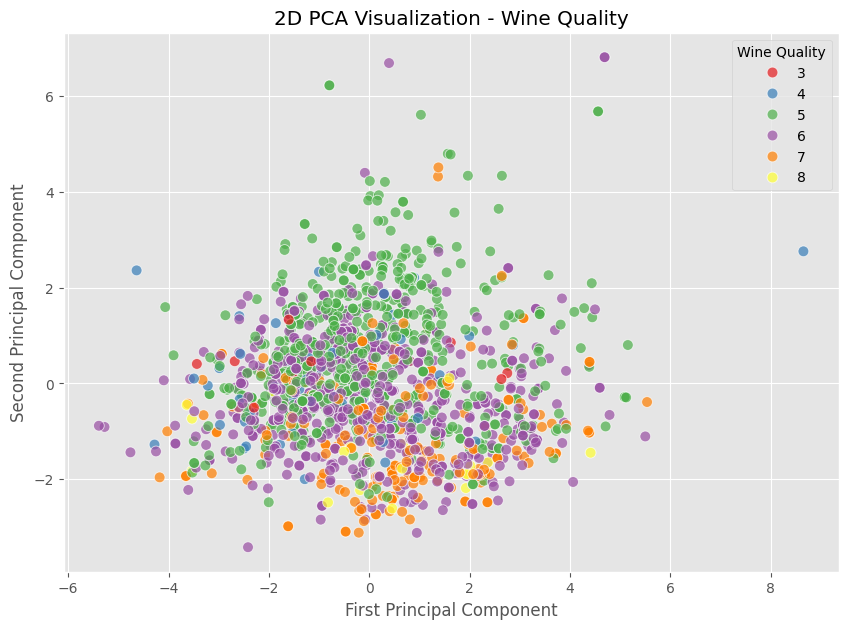

In [33]:
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_2d_df = pd.DataFrame(
    X_pca_2d,
    columns=['PC1', 'PC2']
)

pca_2d_df['quality'] = y.values

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_2d_df,
    x='PC1',
    y='PC2',
    hue='quality',
    palette='Set1',
    s=60,
    alpha=0.7
)

plt.title("2D PCA Visualization - Wine Quality")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend(title="Wine Quality")
plt.grid(True)

plt.show()

In [34]:
pca_3d = PCA(n_components=3)

X_pca_3d = pca_3d.fit_transform(X_scaled)

pca_3d_df = pd.DataFrame(
    X_pca_3d,
    columns=['PC1', 'PC2', 'PC3']
)

pca_3d_df['quality'] = y.values.astype(str)

fig = px.scatter_3d(
    pca_3d_df,
    x='PC1',
    y='PC2',
    z='PC3',
    color='quality',
    title="3D PCA Visualization - Wine Quality",
    labels={
        'PC1': 'Principal Component 1',
        'PC2': 'Principal Component 2',
        'PC3': 'Principal Component 3',
        'quality': 'Wine Quality'
    },
    opacity=0.7
)

fig.update_traces(marker=dict(size=4))

fig.show()

In [35]:
print("PCA VARIANCE SUMMARY")

print("\n2D PCA:")
print(
    "Variance Retained:",
    round(sum(pca_2d.explained_variance_ratio_) * 100, 2),
    "%"
)

print("\n3D PCA:")
print(
    "Variance Retained:",
    round(sum(pca_3d.explained_variance_ratio_) * 100, 2),
    "%"
)

print("\nIndividual Principal Components:")

for i, variance in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {variance*100:.2f}%")

PCA VARIANCE SUMMARY

2D PCA:
Variance Retained: 45.68 %

3D PCA:
Variance Retained: 59.78 %

Individual Principal Components:
PC1: 28.17%
PC2: 17.51%
PC3: 14.10%
PC4: 11.03%
PC5: 8.72%
PC6: 6.00%
PC7: 5.31%
PC8: 3.85%
PC9: 3.13%
PC10: 1.65%
PC11: 0.54%
